# 04 · GA diagnostics and benchmark

How good is the genetic algorithm? On a sample of real windows we compare it with
SciPy's differential evolution (DE) and with multi-start Nelder–Mead (NM), then look
at seed stability and hyperparameter sensitivity.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lppl.data import db
from lppl import viz
viz.apply_style()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
engine = db.get_engine()          # reads POSTGRES_* env vars / .env (see docs/configuration.md)
assert db.ping(engine), "PostgreSQL not reachable - run `make up` first"


In [2]:
import time
from lppl.config import load_config
from lppl.model.calibrate import fit_window
from lppl.model.lppls import dates_to_years
from lppl.optim.ga import GAConfig
cfg = load_config()
rng = np.random.default_rng(2024)
px_all = db.load_all_prices(engine, "adj_close")
# 24 random (ticker, end date, window length) problems from the last 6 years
probs = []
for _ in range(24):
    t = rng.choice(px_all.columns)
    s = px_all[t].dropna().loc["2019-01-01":]
    n = int(rng.choice([250, 500, 750]))
    end = int(rng.integers(n, len(s)))
    probs.append((t, s.iloc[end - n:end]))
len(probs)

24

In [3]:
rows = []
for i, (t, s) in enumerate(probs):
    tt, yy = dates_to_years(s.index), np.log(s.to_numpy())
    for method in ["ga", "de", "nm"]:
        r = fit_window(tt, yy, bounds=cfg.bounds, method=method, ga_config=cfg.ga, rng=np.random.default_rng(i))
        rows.append({"problem": i, "ticker": t, "n": len(s), "method": method, "sse": r.fit.sse,
                     "tc": r.fit.tc, "ms": r.elapsed_ms, "evals": r.n_evals})
bench = pd.DataFrame(rows)
best = bench.groupby("problem")["sse"].transform("min")
bench["sse_excess_%"] = 100 * (bench["sse"] / best - 1)
summary = bench.groupby("method").agg(
    median_ms=("ms", "median"), mean_evals=("evals", "mean"),
    found_best_pct=("sse_excess_%", lambda x: 100 * (x < 0.01).mean()),
    median_excess_pct=("sse_excess_%", "median"), worst_excess_pct=("sse_excess_%", "max")).round(2)
summary

,median_ms,mean_evals,found_best_pct,median_excess_pct,worst_excess_pct
method,,,,,
de,255.50,4241.92,83.33,0.0,6.93
ga,116.56,1351.58,79.17,0.0,4.73
nm,1076.79,3292.25,95.83,0.0,2.94


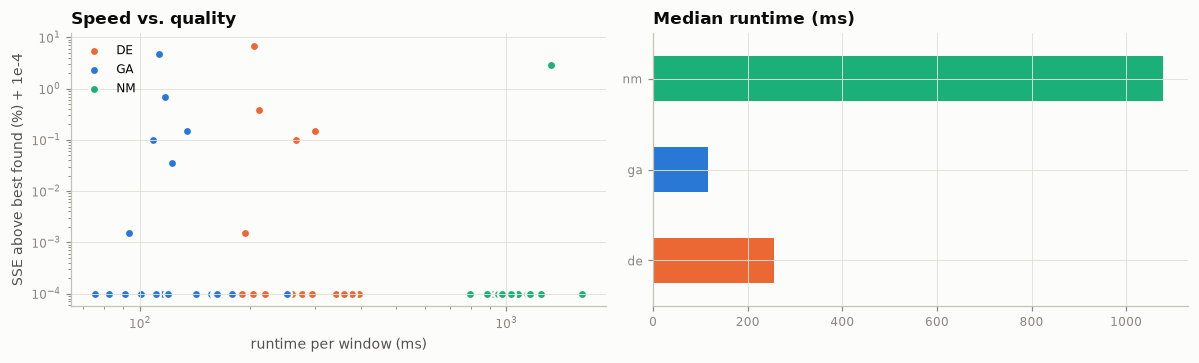

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
colors = {"ga": viz.SERIES[0], "de": viz.SERIES[1], "nm": viz.SERIES[2]}
for m, g in bench.groupby("method"):
    axes[0].scatter(g["ms"], g["sse_excess_%"] + 1e-4, label=m.upper(), color=colors[m], s=36,
                    edgecolor=viz.SURFACE, linewidth=1.5)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("runtime per window (ms)"); axes[0].set_ylabel("SSE above best found (%) + 1e-4")
axes[0].set_title("Speed vs. quality"); axes[0].legend()
summary["median_ms"].plot.barh(ax=axes[1], color=[colors[m] for m in summary.index])
axes[1].set_title("Median runtime (ms)"); axes[1].set_ylabel("")
fig.tight_layout()

## Seed stability of tc

Same window, 20 different seeds. A well-converged optimiser returns the same tc
regardless of seed; spread here reflects a flat or multi-modal cost surface,
which is a property of LPPLS itself (the "sloppiness" of tc).

In [5]:
t, s = probs[0]
tt, yy = dates_to_years(s.index), np.log(s.to_numpy())
seed_rows = []
for seed in range(20):
    for method in ["ga", "de"]:
        r = fit_window(tt, yy, bounds=cfg.bounds, method=method, ga_config=cfg.ga, rng=np.random.default_rng(seed))
        seed_rows.append({"seed": seed, "method": method, "tc": r.fit.tc, "sse": r.fit.sse})
sd = pd.DataFrame(seed_rows)
display(sd.groupby("method").agg(tc_std_days=("tc", lambda x: 365.25 * x.std()), sse_min=("sse", "min"), sse_max=("sse", "max")))

,tc_std_days,sse_min,sse_max
method,,,
de,0.006911,3.601491,3.601491
ga,0.000025,3.601491,3.601491


## GA hyperparameter sensitivity

Population size × generations, with and without the Nelder–Mead polish, averaged
over the first 8 problems. Quality is SSE above the best value any method found.

In [6]:
grid = []
for pop in [20, 40, 80]:
    for gens in [15, 30, 60]:
        for polish in [False, True]:
            c = GAConfig(population_size=pop, generations=gens, polish=polish)
            ex, ms = [], []
            for i, (t, s) in enumerate(probs[:8]):
                tt, yy = dates_to_years(s.index), np.log(s.to_numpy())
                r = fit_window(tt, yy, bounds=cfg.bounds, ga_config=c, rng=np.random.default_rng(i))
                b = bench[bench.problem == i]["sse"].min()
                ex.append(100 * (r.fit.sse / b - 1)); ms.append(r.elapsed_ms)
            grid.append({"population": pop, "generations": gens, "polish": polish,
                         "mean_excess_%": np.mean(ex), "ms": np.mean(ms)})
grid = pd.DataFrame(grid)
grid.pivot_table(index=["polish", "population"], columns="generations", values=["mean_excess_%", "ms"]).round(2)

mean_excess_%                  ms                
generations                  15    30    60      15      30      60
polish population                                                  
False  20                  4.68  1.58  1.14   16.65   31.91   62.91
       40                  2.66  0.25  0.11   33.71   48.50  102.37
       80                  0.76  0.22  0.06   49.01  112.12  186.74
True   20                  0.87  0.87  0.87  100.16  110.00  150.64
       40                  0.08  0.08  0.08  105.42  145.83  166.68
       80                  0.05  0.05  0.05  129.26  178.72  271.93

**Reading the results.**

* **Polish matters more than population size.** With the Nelder–Mead polish on, the result
  barely depends on the number of generations: the GA only has to land in the right basin.
  Without it, many more generations and individuals are needed to reach the same SSE.
* **Population matters for the basin.** Population 20 lands in a worse basin noticeably
  more often than 40 or 80, even when polished.
* **Benchmark.** Multistart Nelder–Mead is the most thorough but several times slower. The
  GA and differential evolution are close in quality, and the GA is the fastest. The
  remaining misses occur on windows with no clear LPPLS structure, where the cost surface
  is flat and several basins have nearly equal SSE. These fits are almost always rejected
  by the qualification filters anyway.
* **Seed stability.** On a window with a clear optimum, tc is reproduced to within minutes
  across seeds, so the dispersion of tc reported by the indicator reflects the data, not
  the optimiser.
